# Evaluation: Grid Search -> Best Model Selection -> Test-Set Report -> XAI Faithfulness

Run this notebook from the `retinopathy-classification-pipeline/` directory (same place `train.py`/`evaluate.py`/`explain.py` live), after checkpoints have been pulled from RunPod into `../checkpoints/`.

1. Load every grid-search run's `best.pt` and compare **validation** macro-F1 (this is what actually picks the winner -- test set is never touched for selection).
2. Pick the best checkpoint per architecture (ConvNeXt-Tiny, DeiT-Small).
3. Run those two winners on the held-out **test set**: classification report, confusion matrices, ROC-AUC.
4. Compare ConvNeXt vs DeiT head-to-head, apply the DR-recall tie-breaker, print the overall winner.
5. Show example correct and incorrect predictions for each winning model.
6. Run Grad-CAM (ConvNeXt) / Attention Rollout (DeiT) + deletion/insertion AUC faithfulness scoring, with qualitative heatmap overlays -- all in this same notebook, no separate script run needed.

In [1]:
import json
import random
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
import torch
import torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from torch.utils.data import DataLoader

from common import RetinaDataset, build_model, build_transforms, confusion_matrix_figure, get_device
from explain import PATCH_GRID, attention_rollout, blur_baseline, deletion_auc, grad_cam, insertion_auc

CHECKPOINT_ROOT = Path("../checkpoints")  # sibling to the pipeline repo, see project topology notes
CLASS_NAMES = json.loads(Path("dataset_splits/class_names.json").read_text())
MODEL_NAMES = {"convnext_tiny": "convnext_tiny", "deit_small": "deit_small_patch16_224"}
XAI_METHOD_FOR_ARCH = {"convnext_tiny": ("grad_cam", grad_cam), "deit_small": ("attention_rollout", attention_rollout)}
DEVICE = get_device()
print(f"device: {DEVICE}, classes: {CLASS_NAMES}")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: mps, classes: ['cataract', 'diabetic_retinopathy', 'glaucoma', 'normal']


## 1. Grid Search Results (Validation Macro-F1)

Every `best.pt` already stores the epoch and validation macro-F1 it was saved at (see `train.py`), so the sweep can be ranked without touching MLflow.

In [2]:
run_pattern = re.compile(r"^(convnext_tiny|deit_small)_lr([\d.e+-]+)_ep(\d+)$")

rows = []
for ckpt_path in sorted(CHECKPOINT_ROOT.glob("*/best.pt")):
    match = run_pattern.match(ckpt_path.parent.name)
    if not match:
        continue  # skip non-sweep dirs (e.g. leftover smoke_test checkpoints)
    arch, lr, epochs_cfg = match.groups()
    ckpt = torch.load(ckpt_path, map_location="cpu")
    rows.append({
        "arch": arch,
        "run": ckpt_path.parent.name,
        "lr": lr,
        "epochs_cfg": int(epochs_cfg),
        "best_epoch": ckpt["epoch"],
        "val_macro_f1": ckpt["val_macro_f1"],
    })

sweep_df = pd.DataFrame(rows).sort_values(["arch", "val_macro_f1"], ascending=[True, False])
sweep_df.reset_index(drop=True, inplace=True)
sweep_df

,arch,run,lr,epochs_cfg,best_epoch,val_macro_f1
0,convnext_tiny,convnext_tiny_lr1e-05_ep30,1e-05,30,11,0.914831
1,convnext_tiny,convnext_tiny_lr1e-05_ep40,1e-05,40,11,0.914785
2,convnext_tiny,convnext_tiny_lr5e-05_ep50,5e-05,50,31,0.913475
3,convnext_tiny,convnext_tiny_lr1e-05_ep50,1e-05,50,11,0.913273
4,convnext_tiny,convnext_tiny_lr1e-05_ep20,1e-05,20,11,0.913188
5,convnext_tiny,convnext_tiny_lr1e-04_ep10,1e-04,10,9,0.913154
6,convnext_tiny,convnext_tiny_lr1e-05_ep10,1e-05,10,5,0.912978
7,convnext_tiny,convnext_tiny_lr5e-05_ep40,5e-05,40,28,0.910208
8,convnext_tiny,convnext_tiny_lr5e-05_ep20,5e-05,20,22,0.910130
9,convnext_tiny,convnext_tiny_lr5e-05_ep30,5e-05,30,12,0.909024


In [3]:
for arch, group in sweep_df.groupby("arch"):
    print(f"--- {arch} (ranked by val macro-F1) ---")
    print(group.to_string(index=False))
    print()

--- convnext_tiny (ranked by val macro-F1) ---
         arch                        run    lr  epochs_cfg  best_epoch  val_macro_f1
convnext_tiny convnext_tiny_lr1e-05_ep30 1e-05          30          11      0.914831
convnext_tiny convnext_tiny_lr1e-05_ep40 1e-05          40          11      0.914785
convnext_tiny convnext_tiny_lr5e-05_ep50 5e-05          50          31      0.913475
convnext_tiny convnext_tiny_lr1e-05_ep50 1e-05          50          11      0.913273
convnext_tiny convnext_tiny_lr1e-05_ep20 1e-05          20          11      0.913188
convnext_tiny convnext_tiny_lr1e-04_ep10 1e-04          10           9      0.913154
convnext_tiny convnext_tiny_lr1e-05_ep10 1e-05          10           5      0.912978
convnext_tiny convnext_tiny_lr5e-05_ep40 5e-05          40          28      0.910208
convnext_tiny convnext_tiny_lr5e-05_ep20 5e-05          20          22      0.910130
convnext_tiny convnext_tiny_lr5e-05_ep30 5e-05          30          12      0.909024
convnext_tiny conv

## 2. Select the Winning Checkpoint per Architecture

In [4]:
winners = sweep_df.loc[sweep_df.groupby("arch")["val_macro_f1"].idxmax()].set_index("arch")
winners

,run,lr,epochs_cfg,best_epoch,val_macro_f1
arch,,,,,
convnext_tiny,convnext_tiny_lr1e-05_ep30,1e-05,30,11,0.914831
deit_small,deit_small_lr1e-04_ep40,1e-04,40,19,0.923419


## 3. Test-Set Evaluation of the Selected Checkpoints

Test set is only used here, once, for the final numbers -- never for picking a checkpoint.

In [5]:
def evaluate_on_test(arch: str, run_name: str, batch_size: int = 32, num_workers: int = 4):
    """Loads `run_name`'s checkpoint for `arch` and runs it over the test set.
    Returns (y_true, y_pred, y_prob, dataset) for downstream reporting/qualitative examples."""
    model = build_model(MODEL_NAMES[arch], num_classes=len(CLASS_NAMES)).to(DEVICE)
    checkpoint = torch.load(CHECKPOINT_ROOT / run_name / "best.pt", map_location=DEVICE, weights_only=True)
    model.load_state_dict(checkpoint["model_state"])
    model.eval()

    eval_tf = build_transforms(model, image_size=224, is_train=False)
    dataset = RetinaDataset("dataset_splits/test.csv", ".", eval_tf)
    loader = DataLoader(dataset, batch_size=batch_size, num_workers=num_workers)

    y_true, y_pred, y_prob = [], [], []
    with torch.no_grad():
        for images, targets in loader:
            probs = F.softmax(model(images.to(DEVICE)), dim=1)
            y_prob += probs.cpu().tolist()
            y_pred += probs.argmax(dim=1).cpu().tolist()
            y_true += targets.tolist()

    return np.array(y_true), np.array(y_pred), np.array(y_prob), dataset


results = {}
for arch, row in winners.iterrows():
    print(f"Running test-set inference for {arch} ({row['run']}) ...")
    y_true, y_pred, y_prob, dataset = evaluate_on_test(arch, row["run"])
    results[arch] = {"run": row["run"], "y_true": y_true, "y_pred": y_pred, "y_prob": y_prob, "dataset": dataset}
print("done.")

Running test-set inference for convnext_tiny (convnext_tiny_lr1e-05_ep30) ...


Running test-set inference for deit_small (deit_small_lr1e-04_ep40) ...


done.


===================== convnext_tiny (convnext_tiny_lr1e-05_ep30) -- TEST SET =====================
                      precision    recall  f1-score   support

            cataract     0.9108    0.9167    0.9137       156
diabetic_retinopathy     0.8770    0.9939    0.9318       165
            glaucoma     0.8550    0.7417    0.7943       151
              normal     0.8734    0.8571    0.8652       161

            accuracy                         0.8799       633
           macro avg     0.8791    0.8774    0.8763       633
        weighted avg     0.8792    0.8799    0.8776       633

ROC-AUC (macro, one-vs-rest): 0.9815
  cataract: 0.9868
  diabetic_retinopathy: 0.9972
  glaucoma: 0.9618
  normal: 0.9803


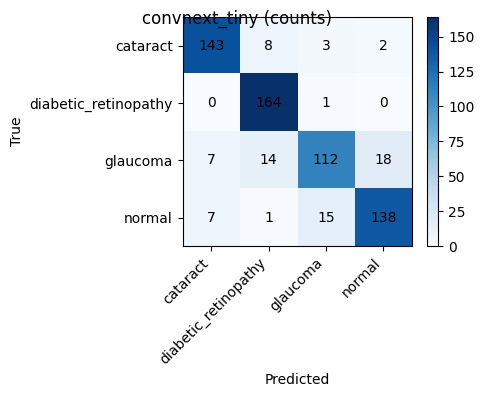

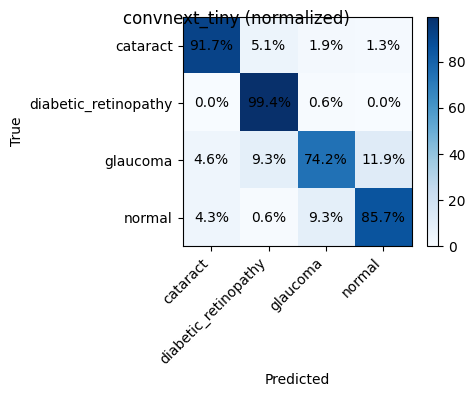


===================== deit_small (deit_small_lr1e-04_ep40) -- TEST SET =====================
                      precision    recall  f1-score   support

            cataract     0.9346    0.9167    0.9256       156
diabetic_retinopathy     0.8778    0.9576    0.9159       165
            glaucoma     0.8626    0.7483    0.8014       151
              normal     0.8462    0.8882    0.8667       161

            accuracy                         0.8799       633
           macro avg     0.8803    0.8777    0.8774       633
        weighted avg     0.8801    0.8799    0.8785       633

ROC-AUC (macro, one-vs-rest): 0.9706
  cataract: 0.9879
  diabetic_retinopathy: 0.9885
  glaucoma: 0.9374
  normal: 0.9687


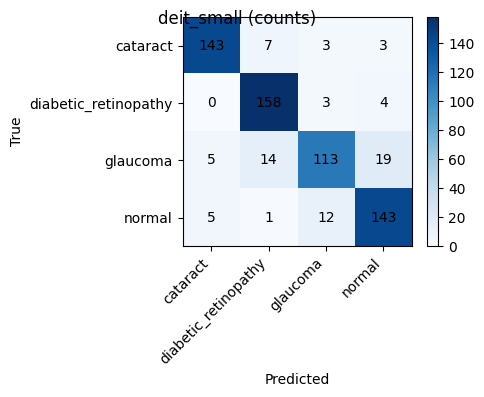

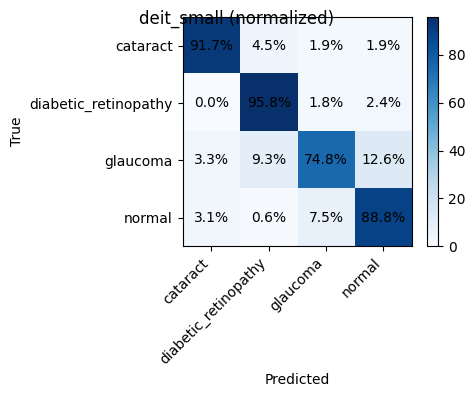

In [6]:
for arch, res in results.items():
    print(f"===================== {arch} ({res['run']}) -- TEST SET =====================")
    report_text = classification_report(res["y_true"], res["y_pred"], target_names=CLASS_NAMES, digits=4)
    print(report_text)

    report_dict = classification_report(
        res["y_true"], res["y_pred"], target_names=CLASS_NAMES, digits=4, output_dict=True
    )
    auc_per_class = roc_auc_score(res["y_true"], res["y_prob"], multi_class="ovr", average=None)
    auc_macro = roc_auc_score(res["y_true"], res["y_prob"], multi_class="ovr", average="macro")
    print(f"ROC-AUC (macro, one-vs-rest): {auc_macro:.4f}")
    for name, auc in zip(CLASS_NAMES, auc_per_class):
        print(f"  {name}: {auc:.4f}")
    results[arch]["report_dict"] = report_dict
    results[arch]["auc_macro"] = auc_macro

    cm = confusion_matrix(res["y_true"], res["y_pred"])
    for normalize in (False, True):
        fig = confusion_matrix_figure(cm, CLASS_NAMES, normalize=normalize)
        fig.suptitle(f"{arch} ({'normalized' if normalize else 'counts'})")
        plt.show()
    print()

## 4. ConvNeXt vs DeiT -- Final Comparison

Selection rule (see `sections/03_methodology.tex`): rank by test macro-F1, break ties with diabetic-retinopathy recall (missing a DR case is the costlier clinical error).

In [7]:
comparison_rows = []
for arch, res in results.items():
    rd = res["report_dict"]
    comparison_rows.append({
        "arch": arch,
        "run": res["run"],
        "accuracy": rd["accuracy"],
        "macro_precision": rd["macro avg"]["precision"],
        "macro_recall": rd["macro avg"]["recall"],
        "macro_f1": rd["macro avg"]["f1-score"],
        "roc_auc_macro": res["auc_macro"],
        "dr_recall": rd["diabetic_retinopathy"]["recall"],
    })
comparison_df = pd.DataFrame(comparison_rows).set_index("arch")
display(comparison_df)

best_f1 = comparison_df["macro_f1"].max()
candidates = comparison_df[comparison_df["macro_f1"] == best_f1]
if len(candidates) > 1:
    winner = candidates["dr_recall"].idxmax()
    print(f"Tie on macro-F1 ({best_f1:.4f}) -> broken by DR recall -> winner: {winner}")
else:
    winner = comparison_df["macro_f1"].idxmax()
    print(f"Winner by test macro-F1: {winner} ({comparison_df.loc[winner, 'macro_f1']:.4f})")

,run,accuracy,macro_precision,macro_recall,macro_f1,roc_auc_macro,dr_recall
arch,,,,,,,
convnext_tiny,convnext_tiny_lr1e-05_ep30,0.879937,0.879053,0.877368,0.876272,0.981535,0.993939
deit_small,deit_small_lr1e-04_ep40,0.879937,0.880292,0.877696,0.877398,0.970638,0.957576


Winner by test macro-F1: deit_small (0.8774)


## 5. Qualitative Predictions -- Correct vs Incorrect Examples

For each winning model, a few correctly-classified and a few misclassified test images, with true label, predicted label, and confidence.

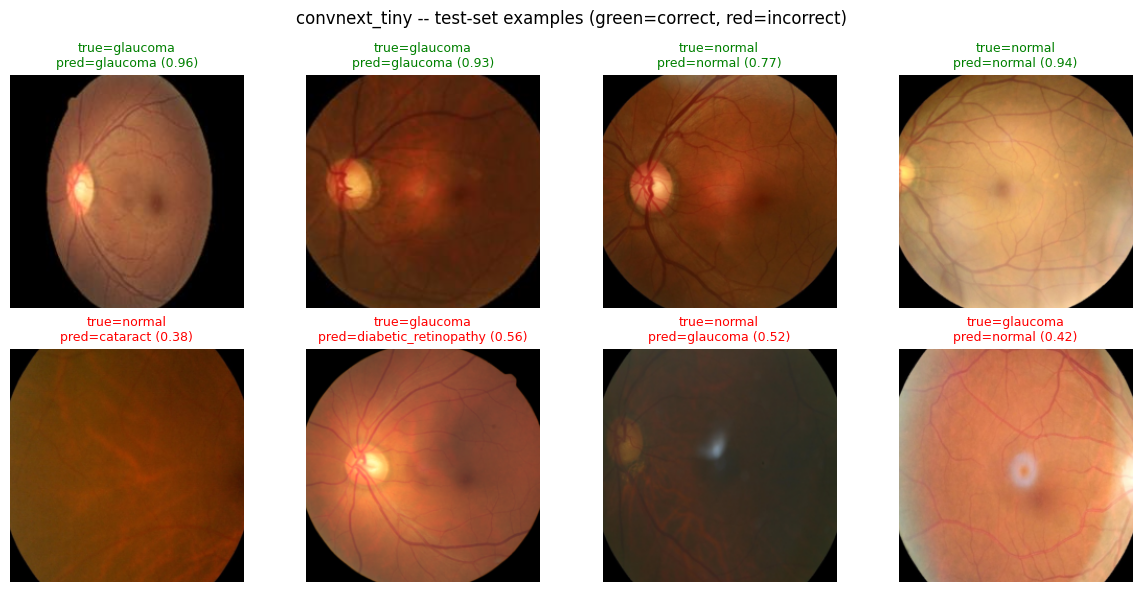

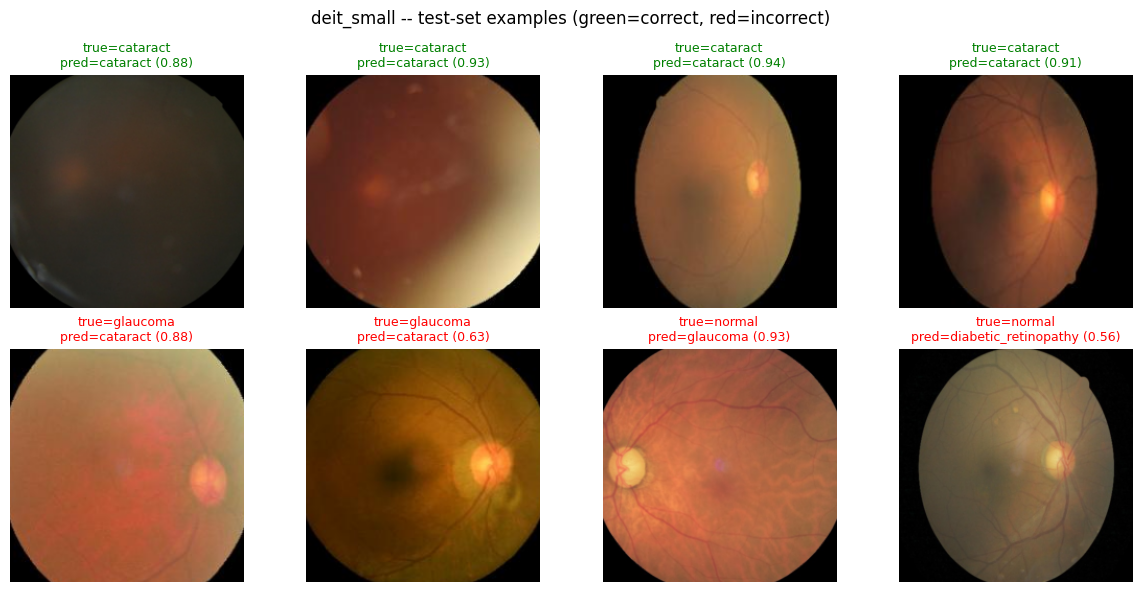

In [8]:
def show_examples(arch: str, n_correct: int = 4, n_wrong: int = 4, seed: int = 0):
    res = results[arch]
    y_true, y_pred, y_prob, dataset = res["y_true"], res["y_pred"], res["y_prob"], res["dataset"]
    rng = np.random.default_rng(seed)

    correct_idx = np.where(y_true == y_pred)[0]
    wrong_idx = np.where(y_true != y_pred)[0]
    picked_correct = rng.choice(correct_idx, size=min(n_correct, len(correct_idx)), replace=False)
    picked_wrong = rng.choice(wrong_idx, size=min(n_wrong, len(wrong_idx)), replace=False)
    picked = list(picked_correct) + list(picked_wrong)

    n_cols = 4
    n_rows = -(-len(picked) // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows))
    axes = np.array(axes).reshape(-1)

    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    for ax, idx in zip(axes, picked):
        image, _ = dataset[idx]
        pixels = (image * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
        is_correct = y_true[idx] == y_pred[idx]
        confidence = y_prob[idx][y_pred[idx]]
        ax.imshow(pixels)
        ax.set_title(
            f"true={CLASS_NAMES[y_true[idx]]}\npred={CLASS_NAMES[y_pred[idx]]} ({confidence:.2f})",
            color="green" if is_correct else "red", fontsize=9,
        )
        ax.axis("off")
    for ax in axes[len(picked):]:
        ax.axis("off")

    fig.suptitle(f"{arch} -- test-set examples (green=correct, red=incorrect)")
    fig.tight_layout()
    plt.show()


for arch in results:
    show_examples(arch)

## 6. Explainability -- Grad-CAM / Attention Rollout + Deletion/Insertion AUC

For each winning checkpoint, run its architecture-appropriate XAI method (ConvNeXt-Tiny -> Grad-CAM, DeiT-Small -> Attention Rollout) over a sample of the test set, and score faithfulness with patch-based deletion/insertion AUC (RISE-style, see `explain.py`). Lower deletion AUC = more faithful; higher insertion AUC = more faithful.

In [9]:
def run_xai(arch: str, run_name: str, num_samples: int = 40, seed: int = 0):
    """Loads `run_name`'s checkpoint for `arch`, runs its architecture-appropriate
    XAI method over `num_samples` random test images, and scores deletion/insertion AUC.
    Returns a dict with the method name and one record per sampled image."""
    method_name, explain_fn = XAI_METHOD_FOR_ARCH[arch]

    model = build_model(MODEL_NAMES[arch], num_classes=len(CLASS_NAMES)).to(DEVICE)
    checkpoint = torch.load(CHECKPOINT_ROOT / run_name / "best.pt", map_location=DEVICE, weights_only=True)
    model.load_state_dict(checkpoint["model_state"])
    model.eval()

    eval_tf = build_transforms(model, image_size=224, is_train=False)
    dataset = RetinaDataset("dataset_splits/test.csv", ".", eval_tf)
    sample_indices = random.Random(seed).sample(range(len(dataset)), min(num_samples, len(dataset)))

    records = []
    for idx in sample_indices:
        image, true_label = dataset[idx]
        image = image.unsqueeze(0).to(DEVICE)
        baseline = blur_baseline(image)

        patch_map, target_class = explain_fn(model, image)
        d_auc = deletion_auc(model, image, patch_map, target_class, baseline)
        i_auc = insertion_auc(model, image, patch_map, target_class, baseline)

        records.append({
            "idx": idx,
            "image": image.detach().cpu(),
            "patch_map": patch_map,
            "true_label": int(true_label),
            "target_class": target_class,
            "deletion_auc": d_auc,
            "insertion_auc": i_auc,
        })

    return {"method": method_name, "records": records}


xai_results = {}
for arch, row in winners.iterrows():
    method_name = XAI_METHOD_FOR_ARCH[arch][0]
    print(f"Running {method_name} + deletion/insertion AUC for {arch} ({row['run']}) ...")
    xai_results[arch] = run_xai(arch, row["run"], num_samples=40)
print("done.")

Running grad_cam + deletion/insertion AUC for convnext_tiny (convnext_tiny_lr1e-05_ep30) ...


Running attention_rollout + deletion/insertion AUC for deit_small (deit_small_lr1e-04_ep40) ...


done.


In [10]:
xai_summary_rows = []
for arch, res in xai_results.items():
    d = [r["deletion_auc"] for r in res["records"]]
    i = [r["insertion_auc"] for r in res["records"]]
    xai_summary_rows.append({
        "arch": arch,
        "xai_method": res["method"],
        "n_samples": len(res["records"]),
        "deletion_auc_mean": float(np.mean(d)),
        "insertion_auc_mean": float(np.mean(i)),
    })
xai_summary_df = pd.DataFrame(xai_summary_rows).set_index("arch")
print("Overall faithfulness (lower deletion / higher insertion = more faithful):")
display(xai_summary_df)

per_class_rows = []
for arch, res in xai_results.items():
    for class_idx, name in enumerate(CLASS_NAMES):
        d = [r["deletion_auc"] for r in res["records"] if r["target_class"] == class_idx]
        i = [r["insertion_auc"] for r in res["records"] if r["target_class"] == class_idx]
        if d:
            per_class_rows.append({
                "arch": arch, "class": name, "n": len(d),
                "deletion_auc_mean": float(np.mean(d)), "insertion_auc_mean": float(np.mean(i)),
            })
per_class_xai_df = pd.DataFrame(per_class_rows)
print("\nPer-class faithfulness:")
display(per_class_xai_df)

Overall faithfulness (lower deletion / higher insertion = more faithful):


,xai_method,n_samples,deletion_auc_mean,insertion_auc_mean
arch,,,,
convnext_tiny,grad_cam,40,0.390625,0.698160
deit_small,attention_rollout,40,0.462579,0.726264



Per-class faithfulness:


,arch,class,n,deletion_auc_mean,insertion_auc_mean
0,convnext_tiny,cataract,12,0.686617,0.655500
1,convnext_tiny,diabetic_retinopathy,10,0.412440,0.892048
2,convnext_tiny,glaucoma,10,0.136300,0.692474
3,convnext_tiny,normal,8,0.237276,0.526898
4,deit_small,cataract,11,0.844693,0.860389
5,deit_small,diabetic_retinopathy,10,0.550491,0.839771
6,deit_small,glaucoma,9,0.088677,0.748447
7,deit_small,normal,10,0.290855,0.445256


### Qualitative Heatmap Overlays

Input image next to its Grad-CAM / Attention Rollout overlay, with predicted class and deletion/insertion AUC for that sample (green title = correctly classified, red = misclassified).

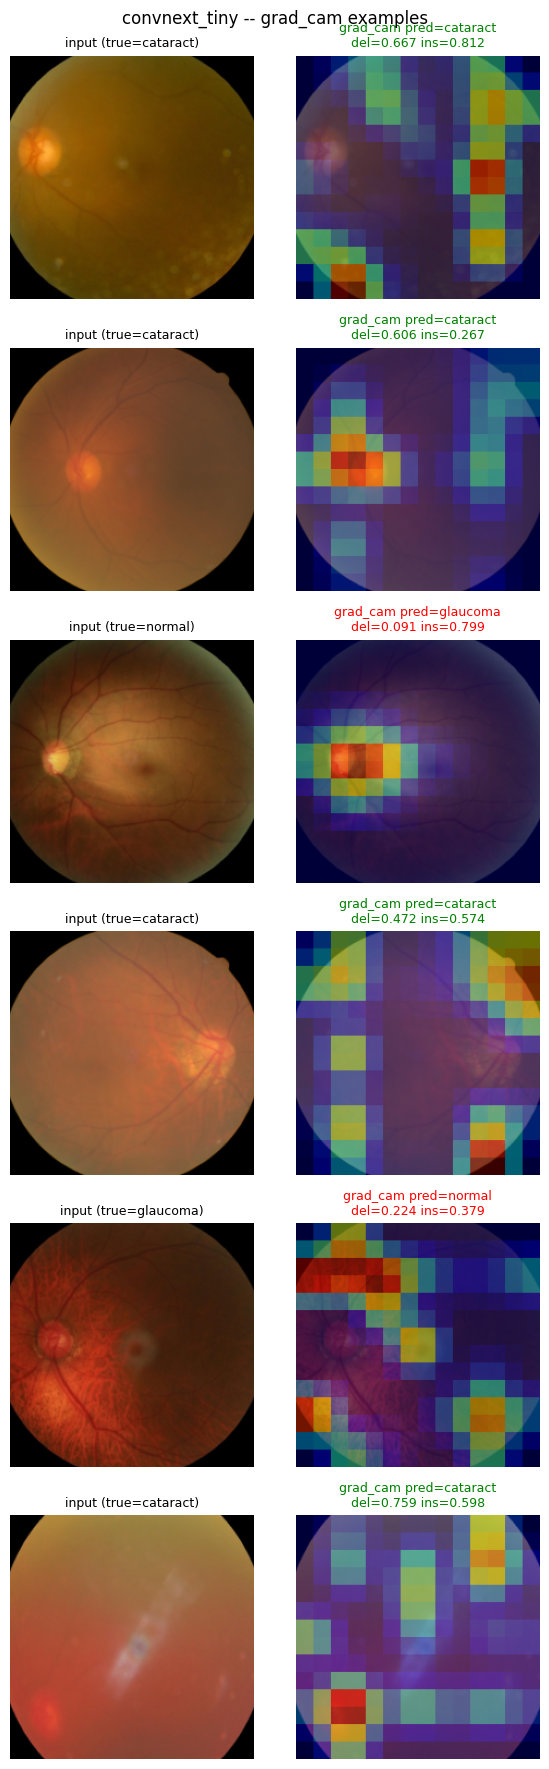

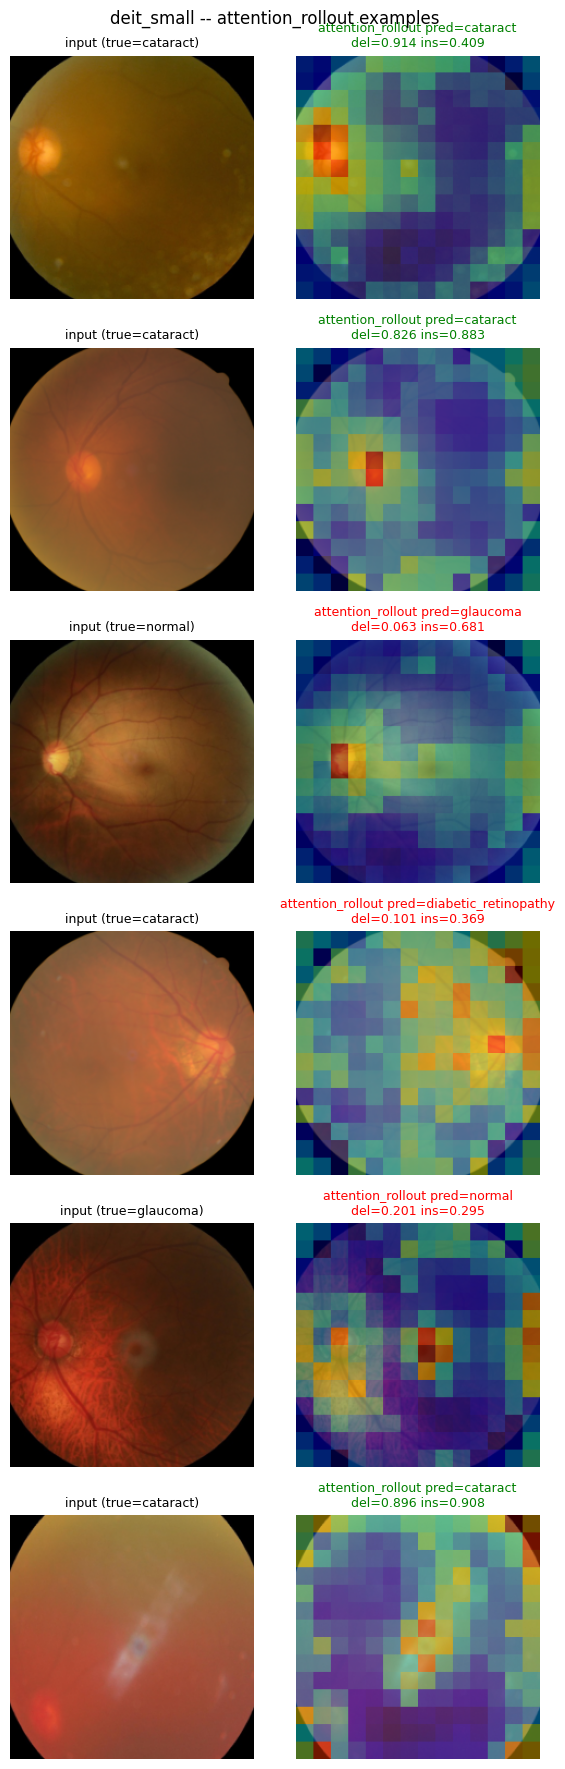

In [11]:
def _denorm(image_tensor, mean, std):
    mean_t = torch.tensor(mean).view(3, 1, 1)
    std_t = torch.tensor(std).view(3, 1, 1)
    pixels = (image_tensor[0].detach().cpu() * std_t + mean_t).clamp(0, 1)
    return pixels.permute(1, 2, 0).numpy()


def show_xai_examples(arch: str, n: int = 6, seed: int = 0):
    res = xai_results[arch]
    method = res["method"]
    records = res["records"]

    model = build_model(MODEL_NAMES[arch], num_classes=len(CLASS_NAMES))
    mean, std = timm.data.resolve_data_config({}, model=model)["mean"], timm.data.resolve_data_config({}, model=model)["std"]

    picked = np.random.default_rng(seed).choice(len(records), size=min(n, len(records)), replace=False)

    fig, axes = plt.subplots(len(picked), 2, figsize=(6, 3 * len(picked)))
    axes = np.atleast_2d(axes)
    for row, p in enumerate(picked):
        rec = records[p]
        rgb = _denorm(rec["image"], mean, std)
        heatmap = np.kron(rec["patch_map"], np.ones((rgb.shape[0] // PATCH_GRID, rgb.shape[1] // PATCH_GRID)))
        pred_name = CLASS_NAMES[rec["target_class"]]
        true_name = CLASS_NAMES[rec["true_label"]]
        is_correct = rec["target_class"] == rec["true_label"]

        axes[row, 0].imshow(rgb)
        axes[row, 0].set_title(f"input (true={true_name})", fontsize=9)
        axes[row, 0].axis("off")

        axes[row, 1].imshow(rgb)
        axes[row, 1].imshow(heatmap, cmap="jet", alpha=0.45)
        axes[row, 1].set_title(
            f"{method} pred={pred_name}\ndel={rec['deletion_auc']:.3f} ins={rec['insertion_auc']:.3f}",
            color="green" if is_correct else "red", fontsize=9,
        )
        axes[row, 1].axis("off")

    fig.suptitle(f"{arch} -- {method} examples")
    fig.tight_layout()
    plt.show()


for arch in xai_results:
    show_xai_examples(arch)